# Exploracao dos Dados — Olist Order Reviews

Exploracao inicial da base de avaliacoes de clientes do dataset Olist.

**Objetivo**: entender o volume, distribuicao e qualidade dos textos disponíveis
para construir a knowledge base do sistema RAG.

## Pre-requisito

Baixe o dataset em https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce/data  
e extraia os CSVs em `../data/raw/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Permite importar src/ a partir de notebooks/
sys.path.insert(0, str(Path().resolve().parent))

DATA_RAW = Path("../data/raw")
DATA_PROCESSED = Path("../data/processed")
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid")

print("Arquivos encontrados em data/raw/:")
for f in sorted(DATA_RAW.glob("*.csv")):
    size_mb = f.stat().st_size / 1_000_000
    print(f"  {f.name:55s}  {size_mb:.1f} MB")

Matplotlib is building the font cache; this may take a moment.


Arquivos encontrados em data/raw/:
  olist_customers_dataset.csv                              9.0 MB
  olist_geolocation_dataset.csv                            61.3 MB
  olist_order_items_dataset.csv                            15.4 MB
  olist_order_payments_dataset.csv                         5.8 MB
  olist_order_reviews_dataset.csv                          14.5 MB
  olist_orders_dataset.csv                                 17.7 MB
  olist_products_dataset.csv                               2.4 MB
  olist_sellers_dataset.csv                                0.2 MB
  product_category_name_translation.csv                    0.0 MB


## 1. Carga dos dados

In [2]:
from src.ingestion import load_enriched_reviews, load_reviews

# Carrega apenas avaliacoes (sem metadados adicionais)
reviews_raw = load_reviews(DATA_RAW)
print(f"Shape (raw): {reviews_raw.shape}")
reviews_raw.head(3)

Shape (raw): (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24


In [3]:
# Carrega com metadados (orders, products) quando disponíveis
reviews = load_enriched_reviews(DATA_RAW)
print(f"Shape (enriched): {reviews.shape}")
print(f"Colunas: {list(reviews.columns)}")

Shape (enriched): (99224, 12)
Colunas: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp', 'order_status', 'purchase_year', 'purchase_month', 'delivery_delta_days', 'product_category_name_english']


## 2. Visao geral e valores ausentes

In [4]:
print("=== Tipos e valores ausentes ===")
info = pd.DataFrame({
    "dtype": reviews.dtypes,
    "missing": reviews.isna().sum(),
    "missing_%": (reviews.isna().mean() * 100).round(2),
})
info

=== Tipos e valores ausentes ===


,dtype,missing,missing_%
review_id,str,0,0.00
order_id,str,0,0.00
review_score,int64,0,0.00
review_comment_title,str,87656,88.34
review_comment_message,str,58247,58.70
review_creation_date,datetime64[us],0,0.00
review_answer_timestamp,datetime64[us],0,0.00
order_status,str,0,0.00
purchase_year,int32,0,0.00
purchase_month,int32,0,0.00


In [5]:
has_title   = reviews["review_comment_title"].notna().sum()
has_message = reviews["review_comment_message"].notna().sum()
has_any     = (reviews["review_comment_title"].notna() | reviews["review_comment_message"].notna()).sum()
total       = len(reviews)

print(f"Total de avaliacoes:          {total:>7,}")
print(f"Com titulo:                   {has_title:>7,}  ({has_title/total*100:.1f}%)")
print(f"Com mensagem:                 {has_message:>7,}  ({has_message/total*100:.1f}%)")
print(f"Com algum texto (titulo|msg): {has_any:>7,}  ({has_any/total*100:.1f}%)")
print(f"Apenas nota, sem texto:       {total - has_any:>7,}  ({(total-has_any)/total*100:.1f}%)")

Total de avaliacoes:           99,224
Com titulo:                    11,568  (11.7%)
Com mensagem:                  40,977  (41.3%)
Com algum texto (titulo|msg):  42,706  (43.0%)
Apenas nota, sem texto:        56,518  (57.0%)


## 3. Distribuicao das notas (review_score)

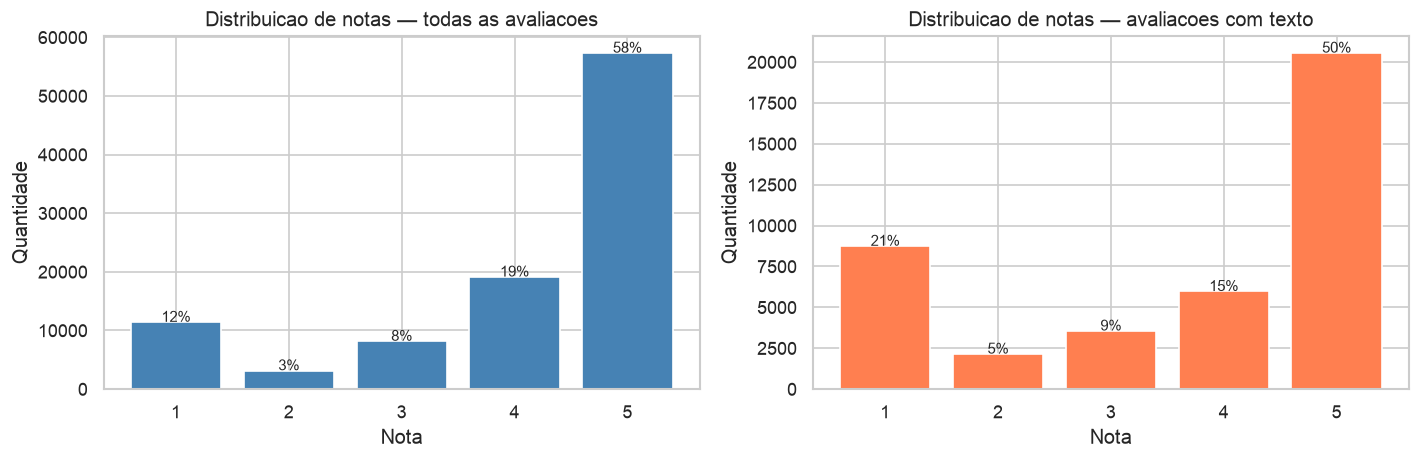

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribuicao geral
score_counts = reviews["review_score"].value_counts().sort_index()
axes[0].bar(score_counts.index, score_counts.values, color="steelblue")
axes[0].set_xlabel("Nota")
axes[0].set_ylabel("Quantidade")
axes[0].set_title("Distribuicao de notas — todas as avaliacoes")
for i, (x, y) in enumerate(zip(score_counts.index, score_counts.values)):
    axes[0].text(x, y + 50, f"{y/total*100:.0f}%", ha="center", fontsize=9)

# Notas apenas entre avaliacoes com texto
reviews_with_text = reviews[reviews["review_comment_message"].notna()]
score_text = reviews_with_text["review_score"].value_counts().sort_index()
axes[1].bar(score_text.index, score_text.values, color="coral")
axes[1].set_xlabel("Nota")
axes[1].set_ylabel("Quantidade")
axes[1].set_title("Distribuicao de notas — avaliacoes com texto")
n_text = len(reviews_with_text)
for i, (x, y) in enumerate(zip(score_text.index, score_text.values)):
    axes[1].text(x, y + 20, f"{y/n_text*100:.0f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("../images/review_score_distribution.png", bbox_inches="tight")
plt.show()

## 4. Analise do comprimento dos textos

In [7]:
from src.ingestion import merge_title_and_message

reviews = merge_title_and_message(reviews)
reviews_text = reviews[reviews["review_text"].notna()].copy()
reviews_text["text_length"] = reviews_text["review_text"].str.len()
reviews_text["word_count"]  = reviews_text["review_text"].str.split().str.len()

print(reviews_text[["text_length", "word_count"]].describe().round(1))

       text_length  word_count
count      42687.0     42687.0
mean          68.9        11.7
std           54.7         9.7
min            1.0         1.0
25%           27.0         4.0
50%           53.0         9.0
75%           95.0        16.0
max          229.0        48.0


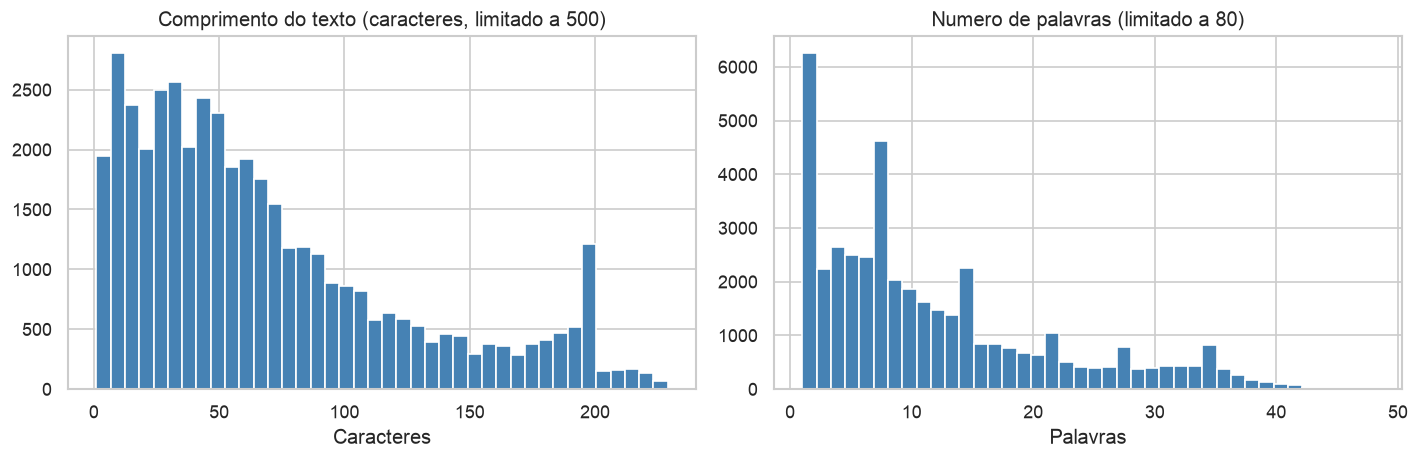

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

reviews_text["text_length"].clip(upper=500).hist(
    bins=40, ax=axes[0], color="steelblue", edgecolor="white"
)
axes[0].set_title("Comprimento do texto (caracteres, limitado a 500)")
axes[0].set_xlabel("Caracteres")

reviews_text["word_count"].clip(upper=80).hist(
    bins=40, ax=axes[1], color="steelblue", edgecolor="white"
)
axes[1].set_title("Numero de palavras (limitado a 80)")
axes[1].set_xlabel("Palavras")

plt.tight_layout()
plt.savefig("../images/review_text_length.png", bbox_inches="tight")
plt.show()

/var/folders/sg/c0_3k_ks4tg0xb82jcsj3npm0000gn/T/ipykernel_79140/2767626290.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


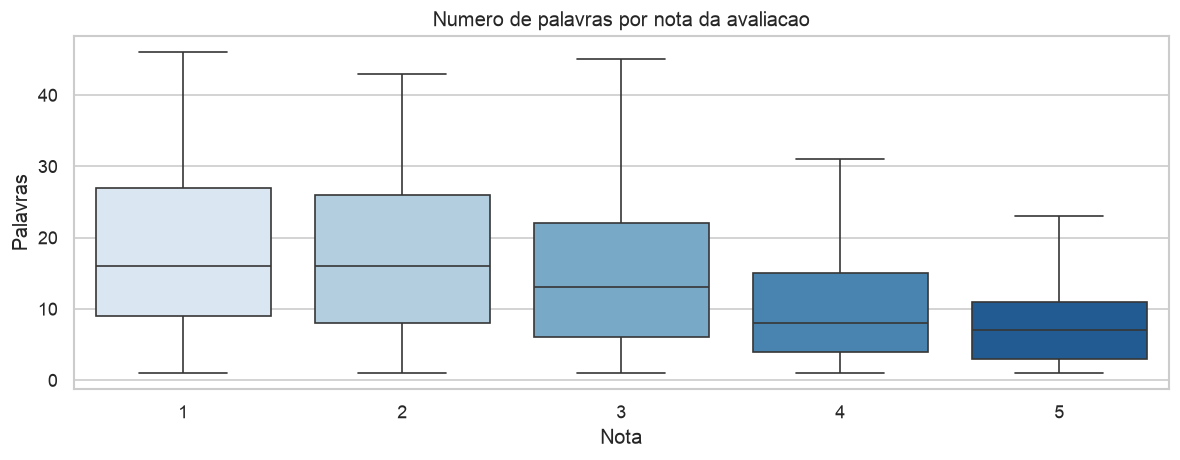

In [9]:
# Comparativo de comprimento por nota
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    data=reviews_text,
    x="review_score",
    y="word_count",
    showfliers=False,
    palette="Blues",
    ax=ax,
)
ax.set_title("Numero de palavras por nota da avaliacao")
ax.set_xlabel("Nota")
ax.set_ylabel("Palavras")
plt.tight_layout()
plt.savefig("../images/word_count_by_score.png", bbox_inches="tight")
plt.show()

## 5. Analise temporal

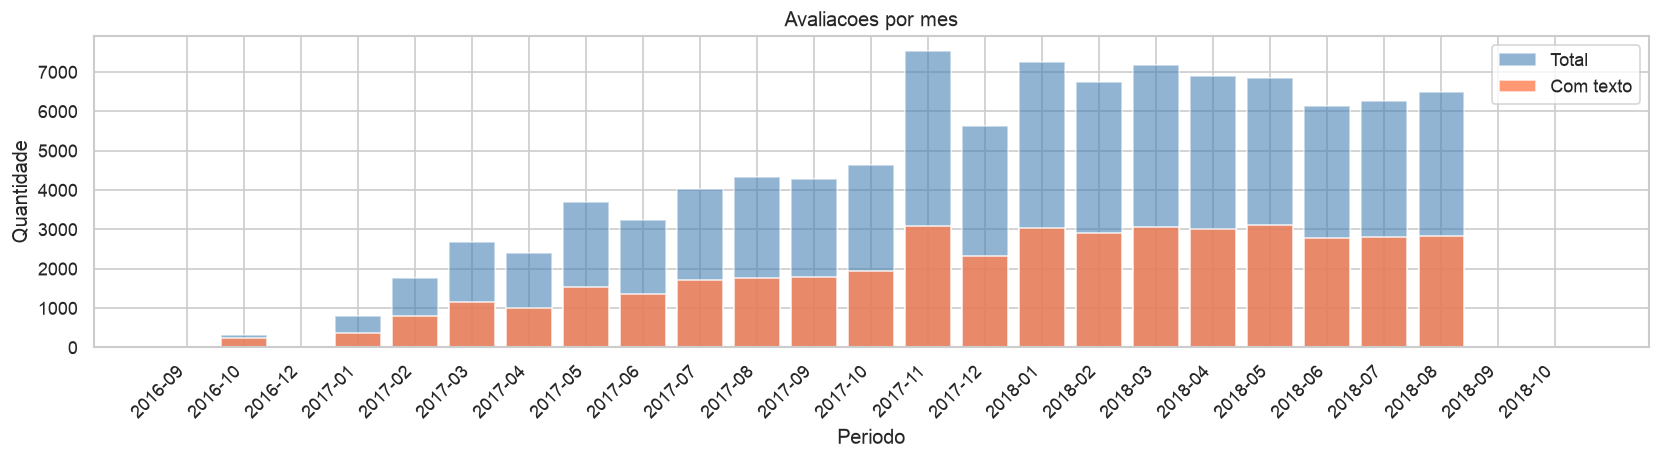

In [10]:
if "purchase_year" in reviews.columns and "purchase_month" in reviews.columns:
    monthly = (
        reviews.dropna(subset=["purchase_year", "purchase_month"])
        .assign(period=lambda d: d["purchase_year"].astype(int).astype(str)
                                 + "-"
                                 + d["purchase_month"].astype(int).astype(str).str.zfill(2))
        .groupby("period")
        .agg(total=("review_id", "count"), with_text=("review_text", "count"))
        .reset_index()
        .sort_values("period")
    )

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.bar(monthly["period"], monthly["total"], label="Total", alpha=0.6, color="steelblue")
    ax.bar(monthly["period"], monthly["with_text"], label="Com texto", alpha=0.8, color="coral")
    ax.set_title("Avaliacoes por mes")
    ax.set_xlabel("Periodo")
    ax.set_ylabel("Quantidade")
    ax.legend()
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig("../images/reviews_per_month.png", bbox_inches="tight")
    plt.show()
else:
    print("Metadados de periodo nao disponíveis (orders CSV ausente).")

## 6. Amostras de avaliacoes por nota

In [11]:
pd.set_option("display.max_colwidth", 200)

for score in [1, 3, 5]:
    sample = (
        reviews_text[reviews_text["review_score"] == score]
        [["review_score", "review_text"]]
        .dropna()
        .sample(min(3, len(reviews_text[reviews_text["review_score"] == score])), random_state=42)
    )
    print(f"\n{'='*70}")
    print(f"NOTA {score}")
    print(f"{'='*70}")
    for _, row in sample.iterrows():
        print(f"  > {row['review_text']}")


NOTA 1
  > não foi entregue a mercadoria
  > recramação. estou esperando a resposta do parceiro,da loja lannister e um resposta porque ate agora so estou me aborecendo,espero que no final de tudo dei certo muito obrigado.
  > Fiz a solicitação de cancelamento do pedido e não obtive resposta da empresa. Ainda por cima consta no site como produto entregue, porém não o recebi.

NOTA 3
  > o produto é bom, porém não resolveu o problema do ronco. Lembrando que não respondi em tempo por que não entendo de computador
  > essa é minha terceira compra e apesar dos imprevistos . super recomendo !
  > O único problema foi que não entregaram em casa, tive que ir retirar no correio

NOTA 5
  > Rápido e eficiente
  > Entrega ok. Recebi 12 dias antes da data fornecida. Eu recomendo
  > super recomendo. ainda não usei mas chegou no prazo combinado


## 7. Categorias de produtos (quando disponível)

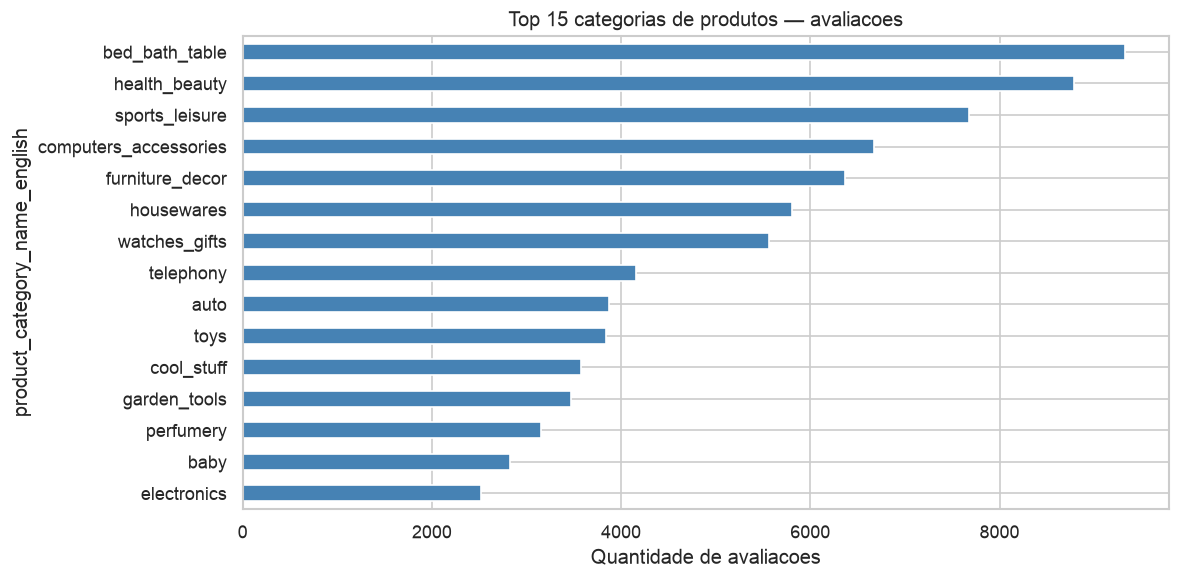

In [12]:
if "product_category_name_english" in reviews.columns:
    top_categories = (
        reviews["product_category_name_english"]
        .value_counts()
        .head(15)
    )
    fig, ax = plt.subplots(figsize=(10, 5))
    top_categories.plot.barh(ax=ax, color="steelblue")
    ax.set_title("Top 15 categorias de produtos — avaliacoes")
    ax.set_xlabel("Quantidade de avaliacoes")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.savefig("../images/top_product_categories.png", bbox_inches="tight")
    plt.show()
else:
    print("Metadados de categoria nao disponíveis (products CSV ausente).")

## 8. Exportacao dos documentos para a knowledge base

In [13]:
import json

from src.ingestion import filter_reviews_with_text, prepare_documents

reviews_clean = filter_reviews_with_text(reviews)
documents = prepare_documents(reviews_clean)

output_path = DATA_PROCESSED / "documents.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(documents, f, ensure_ascii=False, indent=2)

print(f"Documentos exportados: {len(documents):,}")
print(f"Arquivo salvo em: {output_path}")
print(f"\nExemplo de documento:")
print(json.dumps(documents[0], ensure_ascii=False, indent=2))

Documentos exportados: 42,687
Arquivo salvo em: ../data/processed/documents.json

Exemplo de documento:
{
  "text": "Recebi bem antes do prazo estipulado.",
  "metadata": {
    "review_id": "e64fb393e7b32834bb789ff8bb30750e",
    "order_id": "658677c97b385a9be170737859d3511b",
    "review_score": 5,
    "review_creation_date": "2017-04-21T00:00:00",
    "purchase_year": 2017,
    "purchase_month": 4,
    "delivery_delta_days": -20.0,
    "product_category_name_english": "garden_tools"
  }
}


## Resumo

| Indicador | Valor |
|---|---|
| Total de avaliacoes | (ver saida da celula 2) |
| Com texto (titulo ou mensagem) | (ver saida da celula 2) |
| Nota media geral | (ver distribuicao) |

**Proxima etapa**: `02_base_conhecimento.ipynb` — gerar embeddings e construir o vector store a partir dos documentos exportados em `data/processed/documents.json`.